# Participation depth: slider designs

Three design ideas for the Haklay [ref] slider, shown with the same example so they can be compared. Once one is chosen it moves into `profile_viz.ipynb`.

Haklay distinguishes four levels of participant involvement: *crowdsourcing*, *distributed intelligence*, *participatory science* and *extreme citizen science*. Input is one position from 1 to 10 on a slider: the four levels sit at 1, 4, 7 and 10, and the two steps between each pair of levels (2 and 3, 5 and 6, 8 and 9) are for projects that fall in between.

Run the cells top to bottom: the first sets the color theme, the second defines what the three designs share.

In [1]:
# Theme: pick the color family used by all charts (pumpkin, apricot, apple, teal, blueberry, eggplant, dragonfruit)
COLOR_FAMILY = "teal"
PALETTE_FILE = "colorpalette.json"  # path to the palette file, relative to the notebook

import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, to_rgb

with open(Path(PALETTE_FILE)) as f:
    _data = json.load(f)
palette = _data["palettes"]
depth_colors = _data["assignments"]["Participation depth (Haklay)"]["colors"]

families = palette["Color families"]
neutrals = palette["Neutrals"]


def shade(name, family=None):
    """Hex of one shade (lighter, light, base, dark, darker) of a color family."""
    family = family or COLOR_FAMILY
    return families["families"][family][families["shades"].index(name)]


def neutral(role):
    """Hex of a neutral role (background, gridline, axis, text, ...) via the grey ramp."""
    return neutrals["ramp"][neutrals["roles"][role]]


plt.rcParams["font.family"] = "sans-serif"
print(f"Theme: {COLOR_FAMILY}", {s: shade(s) for s in families["shades"]})

Theme: teal {'lighter': '#DDF2EF', 'light': '#98D9D1', 'base': '#56B9B9', 'dark': '#236F7B', 'darker': '#0D2732'}


## Shared by all designs

The four levels, the position scale and a few helpers. The level colors come from the palette file: the four levels are an ordered scale, so they use the sequential palette (light = low depth, dark = high depth), and the steps in between are interpolated.

In [2]:
DEPTH_LEVELS = ["crowdsourcing", "distributed intelligence", "participatory science", "extreme citizen science"]
DEPTH_DESCRIPTIONS = {
    "crowdsourcing": "participants act as sensors or provide computing resources",
    "distributed intelligence": "participants classify, interpret or process information",
    "participatory science": "participants help define the problem and what data to collect",
    "extreme citizen science": "participants shape problem definition, data collection and analysis",
}
N_POSITIONS = 10
LEVEL_POSITIONS = [1, 4, 7, 10]  # the two positions in between each pair of levels are 2-3, 5-6 and 8-9

# sequential colors of the four levels, interpolated to a color for every position
depth_cmap = LinearSegmentedColormap.from_list("depth", [depth_colors[lvl] for lvl in DEPTH_LEVELS])


def check_position(position):
    if position != int(position) or not 1 <= position <= N_POSITIONS:
        raise ValueError(f"position must be a whole number from 1 to {N_POSITIONS}")
    return int(position)


def position_color(position, colors=None):
    """Color of one position on the sequential depth scale."""
    cmap = depth_cmap
    if colors:
        cmap = LinearSegmentedColormap.from_list("depth", [{**depth_colors, **colors}[lvl] for lvl in DEPTH_LEVELS])
    return cmap((position - 1) / (N_POSITIONS - 1))


def position_label(position):
    """Name of the level at this position, or 'between X and Y' for the steps in between."""
    if position in LEVEL_POSITIONS:
        return DEPTH_LEVELS[LEVEL_POSITIONS.index(position)]
    lower = (position - 1) // 3
    return f"between {DEPTH_LEVELS[lower]}\nand {DEPTH_LEVELS[lower + 1]}"


def blend(color, other, t):
    """Mix color with another color: t=0 is color, t=1 is other."""
    a, b = np.array(to_rgb(color)), np.array(to_rgb(other))
    return tuple(a + (b - a) * t)


def readable_on(color, dark, light="white"):
    """Dark or light text, whichever reads better on this fill."""
    r, g, b = to_rgb(color)
    return dark if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.5 else light


def wrap(text, width):
    return "\n".join(textwrap.wrap(text, width))

## Design A: classic slider

A familiar form control: a rounded track, a fill up to the handle and a round handle on top. Small ticks mark the ten positions, longer ones the four levels, which are named underneath. It is the plainest of the three and uses a single theme color, so it matches the other charts in the report. The depth is shown by the handle position only.

Every color can be overridden.

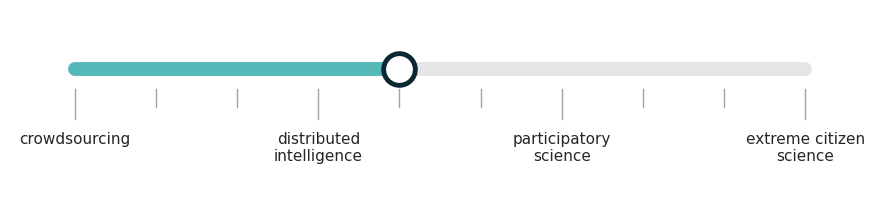

In [3]:
def plot_depth_slider_classic(
    position,
    fill_color=None,    # track up to the handle; default: theme "base"
    handle_edge=None,   # default: theme "darker"
    track_color=None,   # default: light grey
    tick_color=None,    # default: grey
    background="white",
    text_color=None,    # default: neutral text
    figsize=(9, 2.2),
    save_to=None,
):
    """Slider with a handle at one of ten positions between the four Haklay levels.

    position: whole number from 1 (crowdsourcing) to 10 (extreme citizen science).
    """
    position = check_position(position)
    ramp = palette["Neutrals"]["ramp"]
    fill_color = fill_color or shade("base")
    handle_edge = handle_edge or shade("darker")
    track_color = track_color or ramp["grey-200"]
    tick_color = tick_color or ramp["grey-500"]
    text_color = text_color or neutral("text")

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)
    ax.set_xlim(0.2, 10.8)
    ax.set_ylim(-1.3, 0.6)
    ax.axis("off")

    # track, then the filled part up to the handle
    ax.plot([1, N_POSITIONS], [0, 0], color=track_color, linewidth=10, solid_capstyle="round", zorder=1)
    ax.plot([1, position], [0, 0], color=fill_color, linewidth=10, solid_capstyle="round", zorder=2)

    # ticks: short for every position, long for the four levels
    for p in range(1, N_POSITIONS + 1):
        length = 0.3 if p in LEVEL_POSITIONS else 0.18
        ax.plot([p, p], [-0.2, -0.2 - length], color=tick_color, linewidth=1, zorder=1)

    for p, level in zip(LEVEL_POSITIONS, DEPTH_LEVELS):
        ax.text(p, -0.62, wrap(level, 16), ha="center", va="top", fontsize=11, color=text_color, linespacing=1.2)

    ax.scatter([position], [0], s=520, color=background, edgecolor=handle_edge, linewidth=3.5, zorder=4)

    fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, ax


# Example input: a project between distributed intelligence and participatory science
fig, ax = plot_depth_slider_classic(position=5)
plt.show()

## Design B: stepped meter

The slider as ten bars that grow from left to right, like a signal-strength or volume indicator. The height shows the "more depth" direction even without reading the labels, and the bars up to the project's position are filled with the sequential depth colors (light = crowdsourcing, dark = extreme citizen science); the rest stay grey. A small marker above the bar names the exact position, and the four levels are labeled under their bars.

It reads as a scale rather than a control, and the color doubles as a second encoding of the same value. Every color can be overridden.

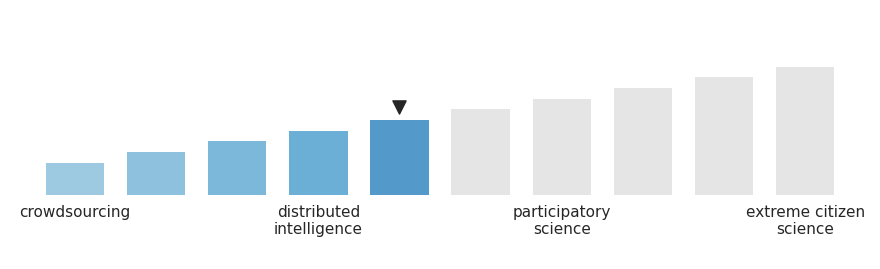

In [4]:
def plot_depth_slider_steps(
    position,
    colors=None,         # {level: hex}; default: depth colors from the palette file
    empty_color=None,    # bars beyond the position; default: light grey
    marker_color=None,   # default: neutral text
    background="white",
    text_color=None,     # default: neutral text
    figsize=(9, 2.8),
    save_to=None,
):
    """Ten growing bars, filled up to one of ten positions between the four Haklay levels.

    position: whole number from 1 (crowdsourcing) to 10 (extreme citizen science).
    """
    position = check_position(position)
    ramp = palette["Neutrals"]["ramp"]
    empty_color = empty_color or ramp["grey-200"]
    text_color = text_color or neutral("text")
    marker_color = marker_color or text_color

    xs = np.arange(1, N_POSITIONS + 1)
    heights = 0.25 + 0.75 * (xs - 1) / (N_POSITIONS - 1)
    fills = [position_color(p, colors) if p <= position else empty_color for p in xs]

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)
    ax.set_xlim(0.2, 10.8)
    ax.set_ylim(-0.5, 1.45)
    ax.axis("off")

    ax.bar(xs, heights, width=0.72, color=fills, linewidth=0, zorder=2)

    # marker above the bar at the project's position
    ax.scatter([position], [heights[position - 1] + 0.1], marker="v", s=90, color=marker_color, zorder=3)

    for p, level in zip(LEVEL_POSITIONS, DEPTH_LEVELS):
        ax.text(p, -0.07, wrap(level, 16), ha="center", va="top", fontsize=11, color=text_color, linespacing=1.2)

    fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, ax


fig, ax = plot_depth_slider_steps(position=5)
plt.show()

## Design C: annotated gradient

The richest of the three: a continuous track that shades from light to dark along the sequential depth colors, with the part beyond the project's position faded out. A callout above the handle spells out where the project sits (a level name, or "between X and Y" for the steps in between), and every level carries a one-line description of what participants do, taken from Haklay's definitions.

This one explains itself, so it can be read without the questionnaire, at the cost of more text and a wider figure. Every color can be overridden.

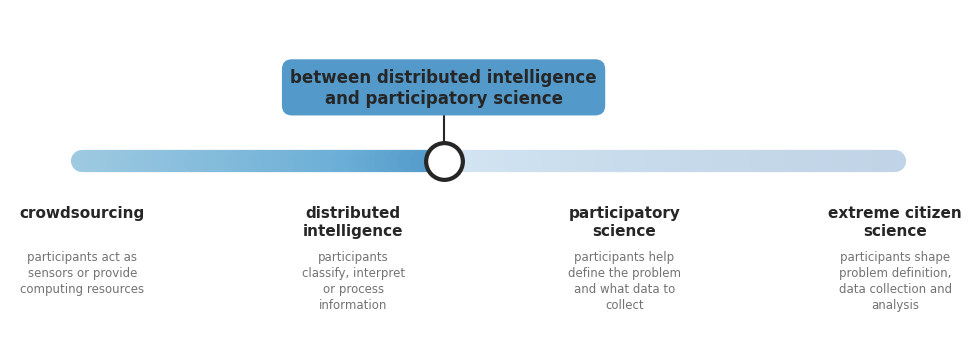

In [5]:
def plot_depth_slider_annotated(
    position,
    colors=None,         # {level: hex}; default: depth colors from the palette file
    fade=0.75,           # how far the track beyond the position fades towards the background (0-1)
    handle_edge=None,    # default: neutral text
    background="white",
    text_color=None,     # default: neutral text
    muted_color=None,    # level descriptions; default: dark grey
    figsize=(10, 3.6),
    save_to=None,
):
    """Gradient track with a callout at one of ten positions between the four Haklay levels.

    position: whole number from 1 (crowdsourcing) to 10 (extreme citizen science).
    """
    position = check_position(position)
    ramp = palette["Neutrals"]["ramp"]
    text_color = text_color or neutral("text")
    handle_edge = handle_edge or text_color
    muted_color = muted_color or ramp["grey-600"]

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)
    ax.set_xlim(0.2, 10.8)
    ax.set_ylim(-2.0, 1.7)
    ax.axis("off")

    # track: many short, overlapping, round-capped segments make a smooth gradient with round ends
    grid = np.linspace(1, N_POSITIONS, 181)
    segments = [[(a, 0), (b, 0)] for a, b in zip(grid[:-1], grid[1:])]
    seg_colors = [blend(position_color((a + b) / 2, colors), background, 0 if b <= position else fade)
                  for a, b in zip(grid[:-1], grid[1:])]
    ax.add_collection(LineCollection(segments, colors=seg_colors, linewidths=16, capstyle="round", zorder=1))

    # handle and callout
    fill = position_color(position, colors)
    ax.scatter([position], [0], s=700, color=background, edgecolor=handle_edge, linewidth=3, zorder=4)
    ax.plot([position, position], [0.2, 0.55], color=handle_edge, linewidth=1.5, zorder=3)
    ax.text(position, 0.6, position_label(position), ha="center", va="bottom", fontsize=12, fontweight="bold",
            color=readable_on(fill, text_color), linespacing=1.25, zorder=5,
            bbox=dict(boxstyle="round,pad=0.5,rounding_size=0.6", facecolor=fill, edgecolor="none"))

    # level names with what participants do
    for p, level in zip(LEVEL_POSITIONS, DEPTH_LEVELS):
        ax.text(p, -0.5, wrap(level, 16), ha="center", va="top", fontsize=11, fontweight="bold",
                color=text_color, linespacing=1.2)
        ax.text(p, -1.0, wrap(DEPTH_DESCRIPTIONS[level], 20), ha="center", va="top", fontsize=8.5,
                color=muted_color, linespacing=1.3)

    fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, ax


fig, ax = plot_depth_slider_annotated(position=5)
plt.show()

## Comparing the designs

The same designs at the lowest, a middle and the highest position, to check that the handle, fill and callout hold up at the edges.

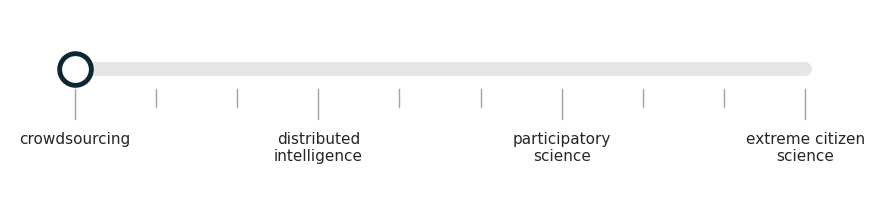

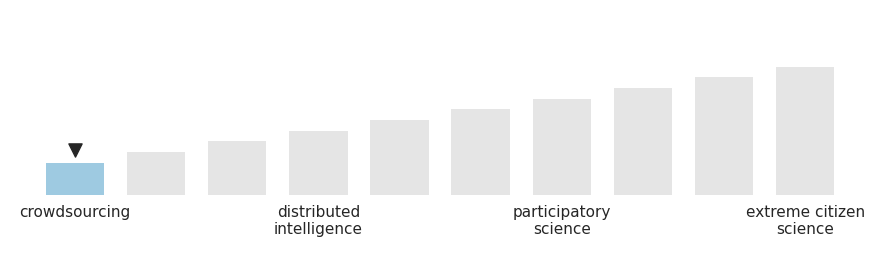

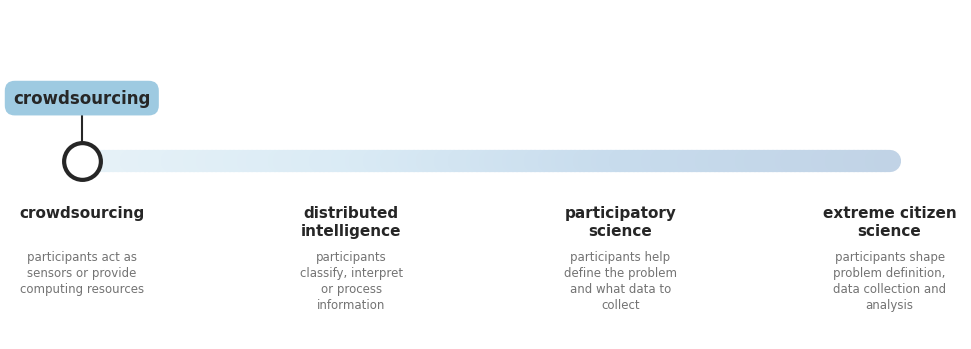

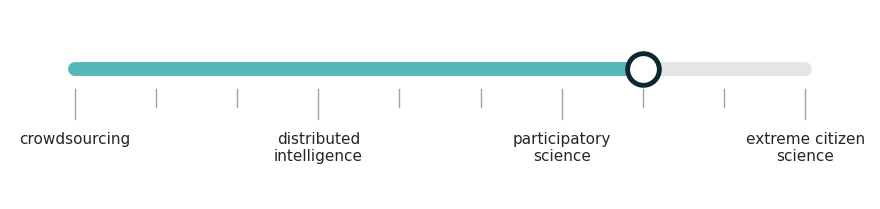

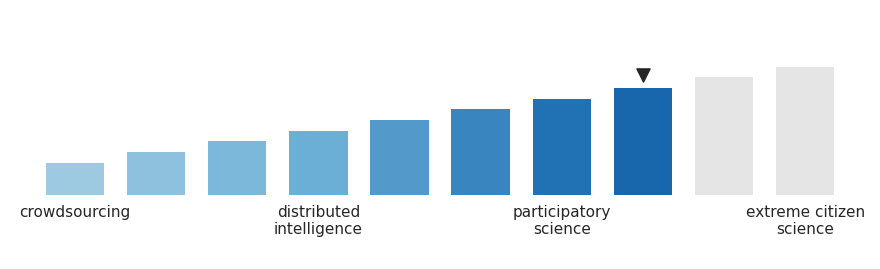

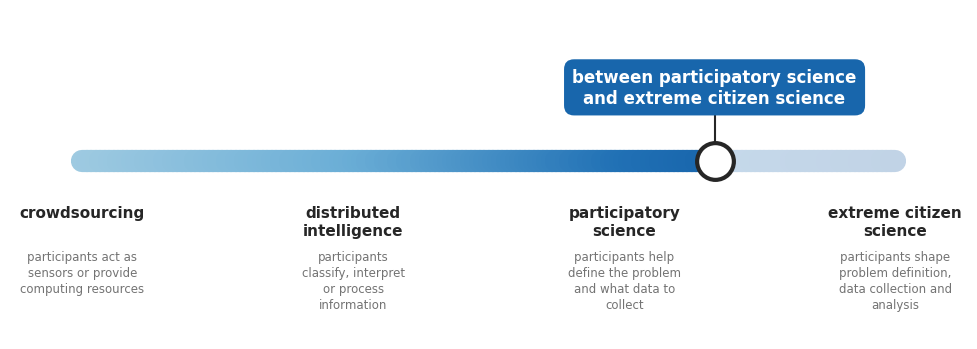

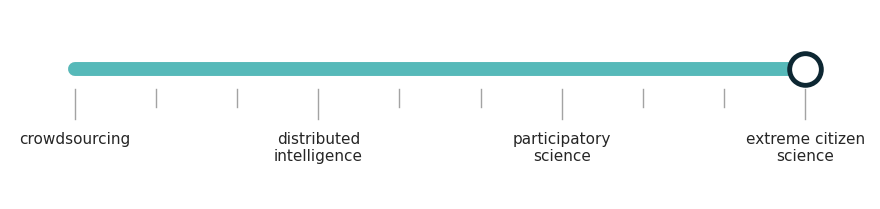

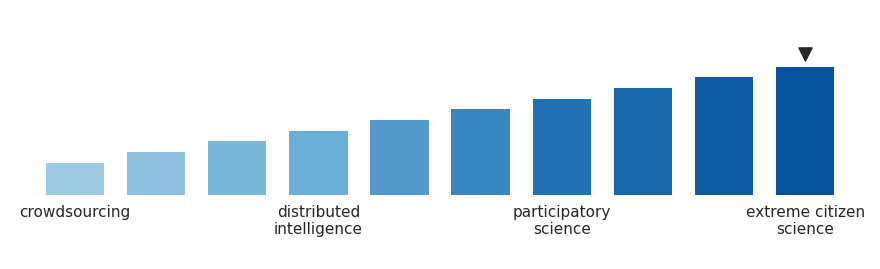

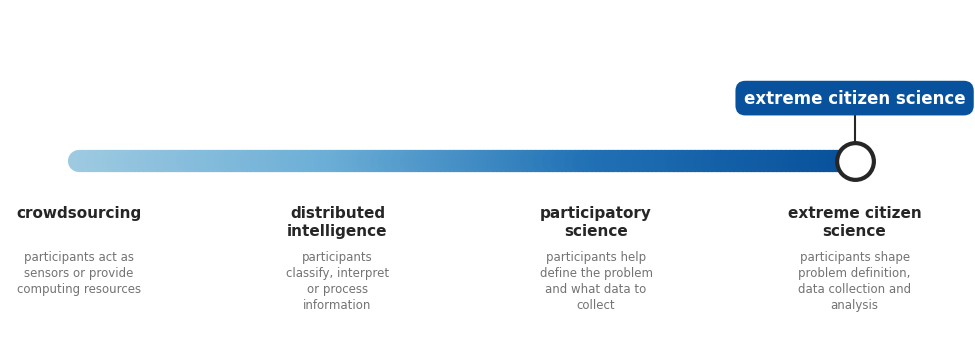

In [6]:
for position in (1, 8, 10):
    plot_depth_slider_classic(position)
    plot_depth_slider_steps(position)
    plot_depth_slider_annotated(position)
plt.show()